In [2]:
!nproc
!free -h

2
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.1Gi       9.1Gi       2.2Mi       2.7Gi        11Gi
Swap:             0B          0B          0B


In [7]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/DSCI2334/cafe_sales.csv', parse_dates=['date'])

print(df.shape)
print(df['date'].min().date(), df['date'].max().date())
print(df['branch'].nunique(),'Branches')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(3170, 9)
2026-01-01 2026-06-30
4 Branches


In [8]:
print(df.groupby('branch')['total_sar'].sum().sort_values(ascending=False))
print(df.groupby('product')['quantity'].sum().sort_values(ascending=False).head(1))

branch
Olaya         23537
Al Malqa      18827
Al Nakheel    17939
Diriyah       14567
Name: total_sar, dtype: int64
product
Spanish Latte    927
Name: quantity, dtype: int64


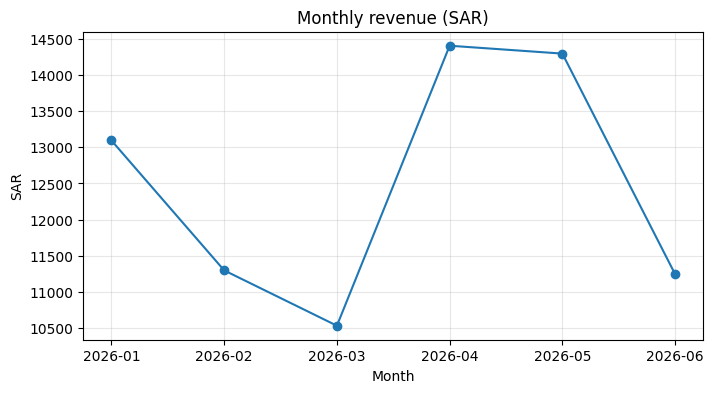

In [9]:
import matplotlib.pyplot as plt
monthly = df.groupby(df['date'].dt.to_period('M'))['total_sar'].sum()
monthly.index = monthly.index.astype(str)

monthly.plot(kind='line', marker='o', figsize=(8,4), title='Monthly revenue (SAR)')
plt.ylabel('SAR'); plt.xlabel('Month'); plt.grid(alpha=.3); plt.show()